# MiTA: configuration, schematic, results and routing

Code: `models/mita/` (module + `__init__.py` builder), configs: `models/mita/configs/*.yaml`.
Deviations from the reference: docs/deviations.md. Variants: docs/variant_registry.md.

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "backbone").exists():        # works from notebooks/ or models/<s>/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
from backbone.paths import DATA_ROOT, RUNS_ROOT, FIG_ROOT
import pandas as pd
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("project:", ROOT); print("data:", DATA_ROOT); print("runs:", RUNS_ROOT)

project: /home/claude/work/MoE_Structures_v2
data: /home/claude/work/MoE_Structures_v2/_data
runs: /home/claude/work/MoE_Structures_v2/runs


In [2]:
from backbone.config import list_variants, load_yaml, variant_path
for v in list_variants("mita"):
    print(f"--- {v}"); print(json.dumps(load_yaml(variant_path("mita", v)).get("structure_params", {})))

--- default
{"num_landmarks": 8, "kv_topk": 8, "router_topk": 1, "shared": true, "lb_coef": 0.01}
--- m16k16
{"num_landmarks": 16, "kv_topk": 16, "router_topk": 1, "shared": true, "lb_coef": 0.01}
--- m4k4
{"num_landmarks": 4, "kv_topk": 4, "router_topk": 1, "shared": true, "lb_coef": 0.01}
--- noshared
{"num_landmarks": 8, "kv_topk": 8, "router_topk": 1, "shared": false, "lb_coef": 0.01}
--- s2
{"num_landmarks": 8, "kv_topk": 8, "router_topk": 2, "shared": true, "lb_coef": 0.01}


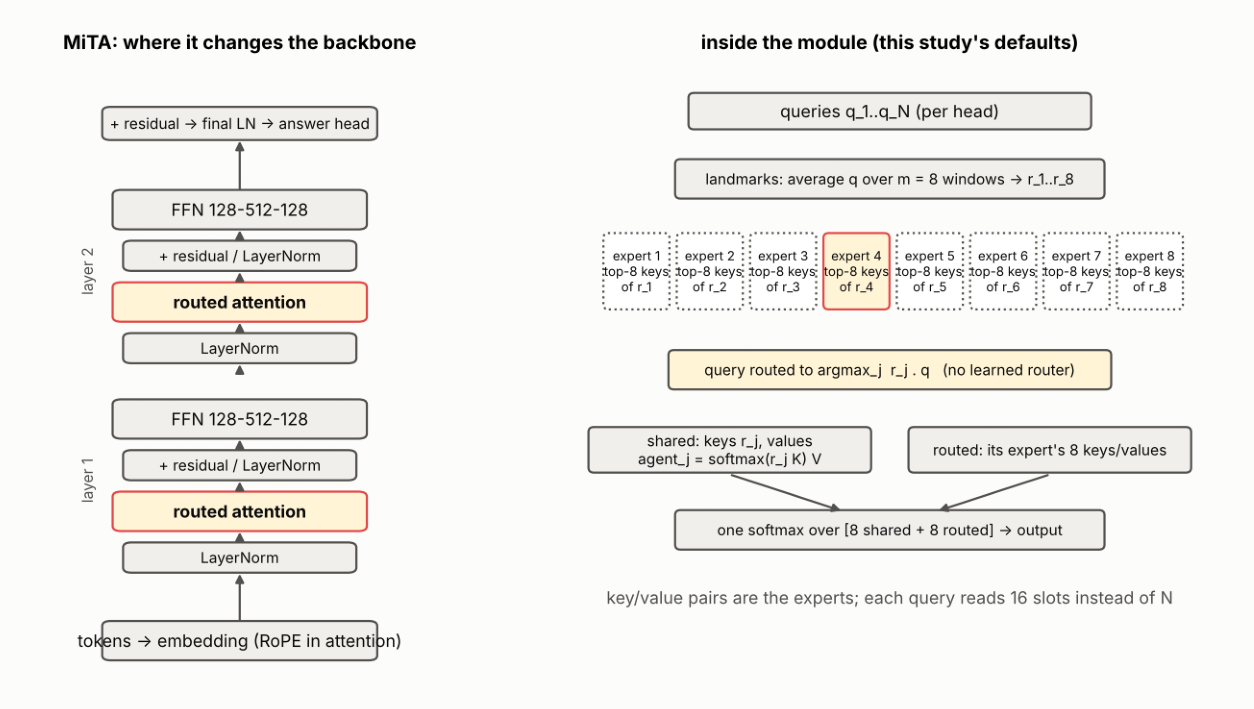

In [3]:
from analysis.schematics import draw
import matplotlib.pyplot as plt, matplotlib.image as mpimg
def show(p, size=(11, 5.5)):
    if p: plt.figure(figsize=size); plt.imshow(mpimg.imread(p)); plt.axis("off"); plt.show()
show(draw("mita"))

In [4]:
from analysis.collect import load_results, load_routing, agg
from analysis import figures as F
df = load_results(RUNS_ROOT); d = df[df.structure == "mita"]
if len(d):
    t = agg(d, ["dataset", "variant", "balance"])
    display(t.pivot_table(index=["dataset", "variant"], columns="balance", values="mean").round(3))
else:
    print("no finished runs yet")

balance              lb   none  warmup
dataset variant                       
copy    default     NaN  0.965     NaN
fact    default   0.213  0.222   0.214
        m16k16    0.438  0.440   0.457
        m4k4      0.056  0.079   0.075
        noshared  0.092  0.092   0.112
        s2        0.222  0.232   0.228
logic   default     NaN  0.580     NaN
mix     default     NaN  0.587     NaN
mod     default   0.213  0.248   0.252
mqar    default     NaN  0.125     NaN
rev     default     NaN  0.952     NaN

entropy  max_load  dead
dataset variant  balance                         
copy    default  none       0.977     0.167   0.0
fact    default  lb         0.999     0.135   0.0
                 none       0.999     0.142   0.0
                 warmup     0.998     0.150   0.0
        m16k16   lb         0.995     0.092   0.0
                 none       0.971     0.145   0.0
                 warmup     0.960     0.172   0.0
        m4k4     lb         1.000     0.260   0.0
                 none       0.999     0.264   0.0
                 warmup     1.000     0.262   0.0
        noshared lb         1.000     0.137   0.0
                 none       0.998     0.150   0.0
                 warmup     0.997     0.159   0.0
        s2       lb         0.998     0.139   0.0
                 none       0.999     0.142   0.0
                 warmup     0.998     0.150   0.0
logic   default  none       0.998     0.145   0.0
mix     default  none       0.997     0.147   0.0
mod     default  lb         1.000     0.129   0.0
                 none       0.997     0.144   0.0
                 warmup     0.989     0.148   0.0
mqar    default  none       0.972     0.204   0.0
rev     default  none       0.959     0.209   0.0

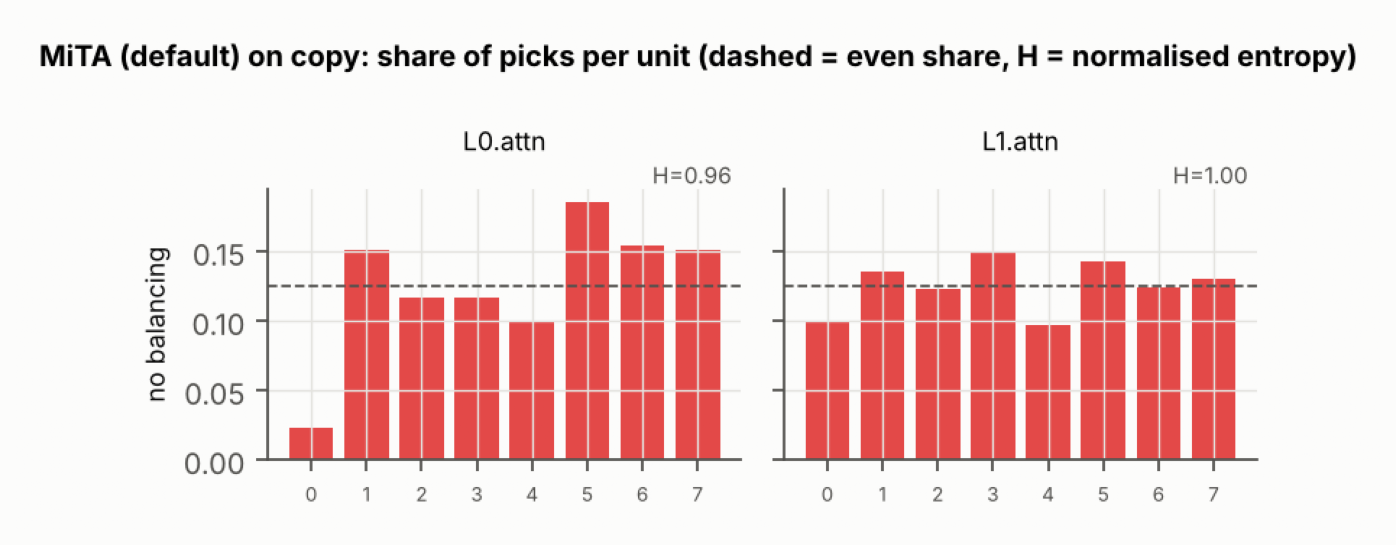

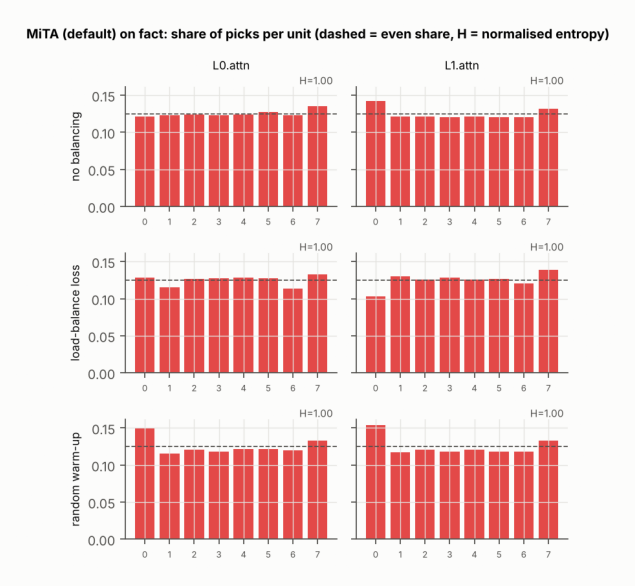

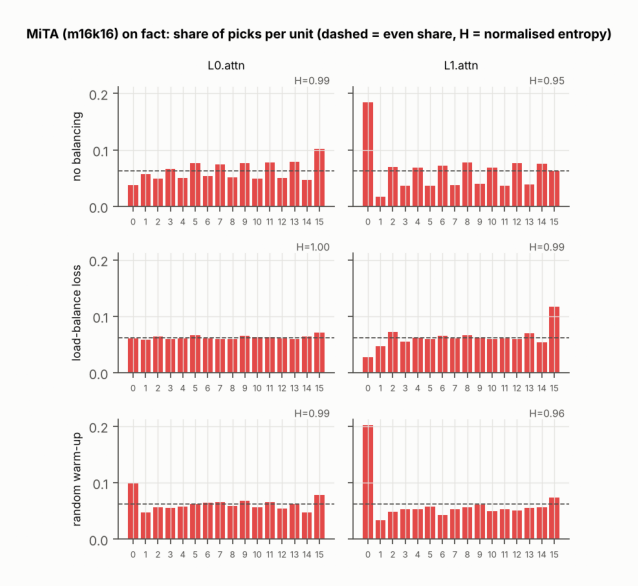

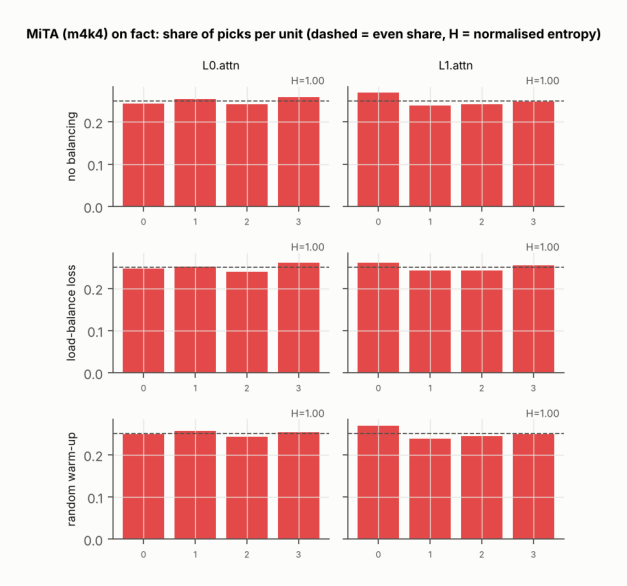

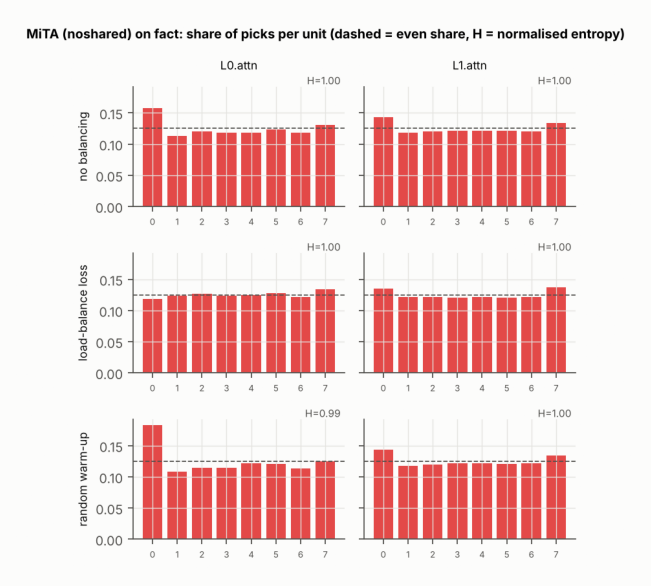

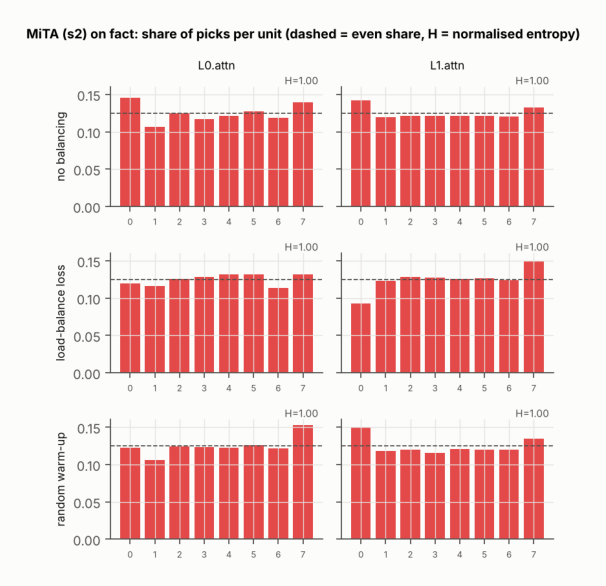

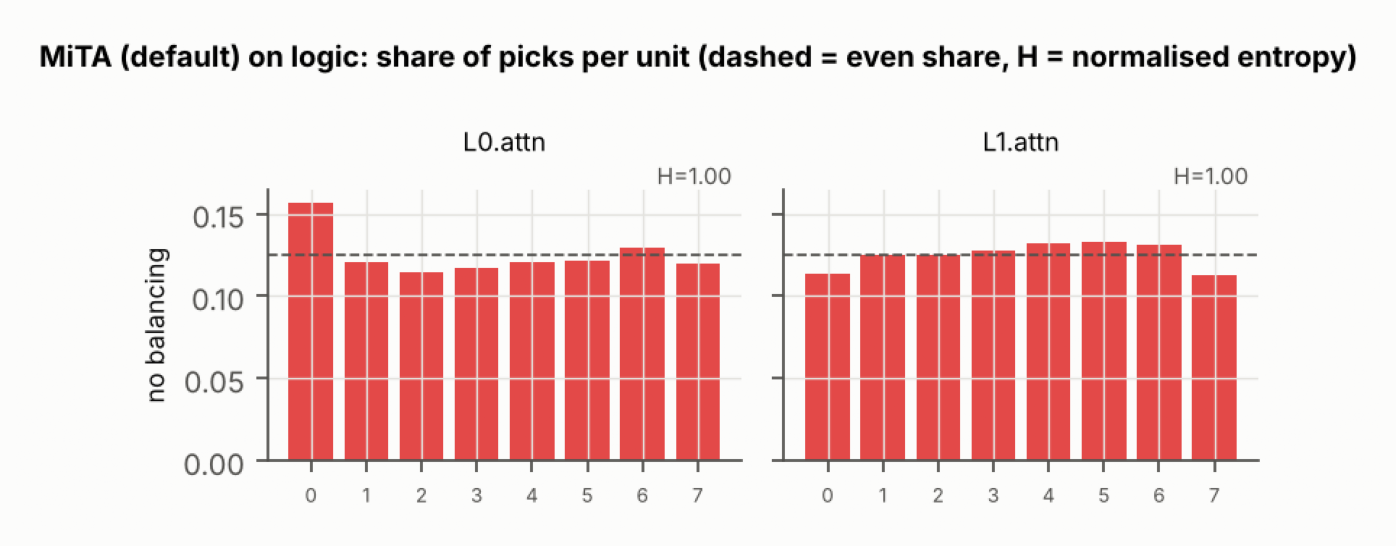

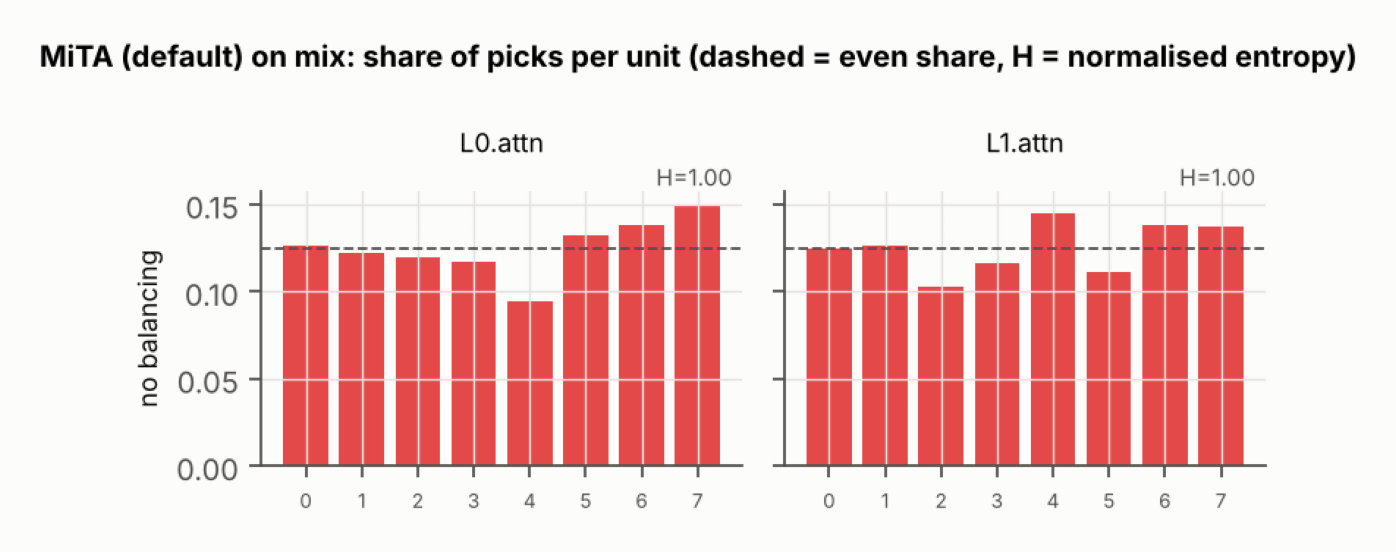

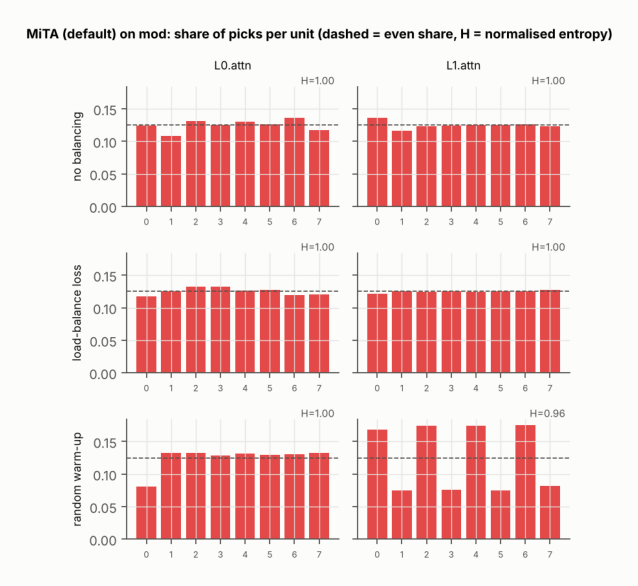

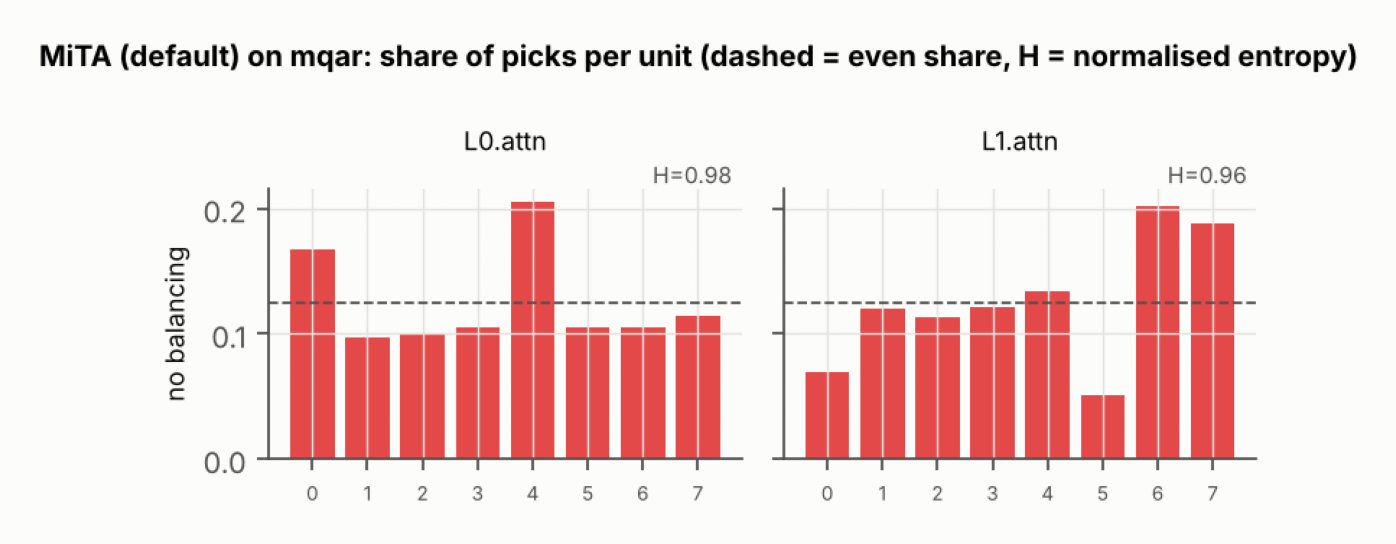

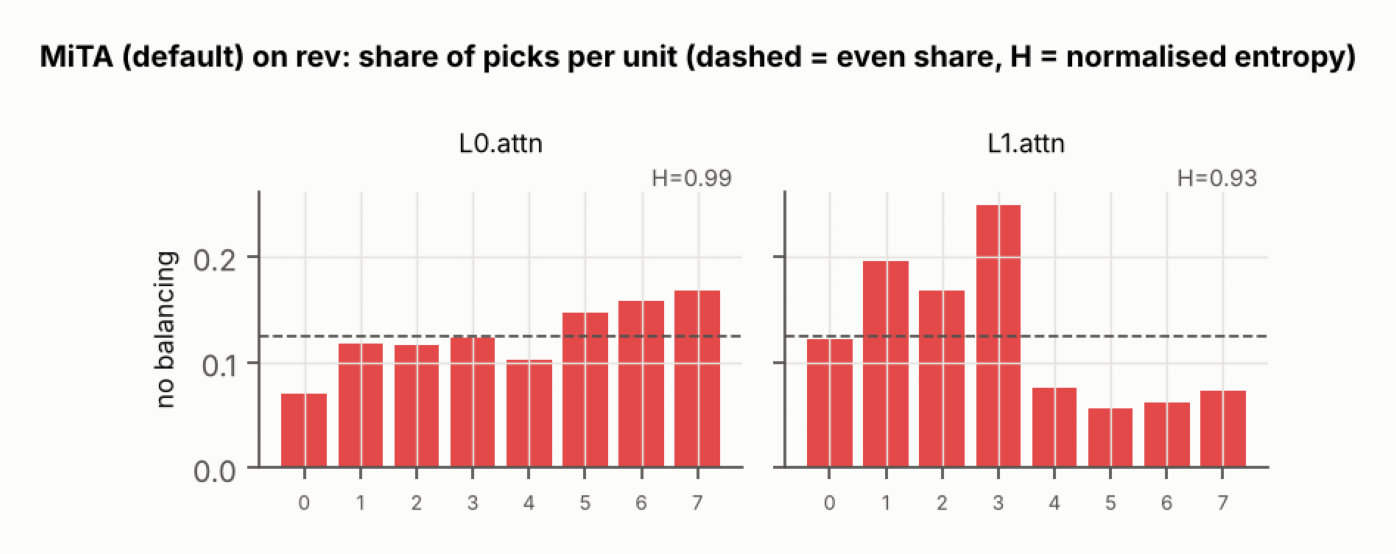

In [5]:
rdf = load_routing(RUNS_ROOT)
if len(rdf) and "mita" in set(rdf.structure):
    r = rdf[rdf.structure == "mita"]
    display(r.groupby(["dataset", "variant", "balance"])[["entropy", "max_load", "dead"]].mean().round(3))
    for ds in sorted(set(r.dataset)):
        for v in sorted(set(r[r.dataset == ds].variant)):
            show(F.routing_load(rdf, ds, "mita", v), (11, 4.5))